# RoDA + Contrast Shift Detection and Correction

In [1]:
import torch
torch.cuda.is_available()

True

In [2]:
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
CUDA build: 13.0
CUDA available: True
GPU count: 1
GPU: NVIDIA GeForce RTX 2060 with Max-Q Design


In [3]:
from dataclasses import dataclass
import pandas as pd
import torch
from typing import Tuple
import torchvision.transforms as T
import torchvision.transforms.functional as F
import os,glob, random
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.model_selection import train_test_split
from imagecorruptions import corrupt
import torch.nn as nn
import torch.nn.functional as Fn
from torchvision.models import wide_resnet50_2, Wide_ResNet50_2_Weights
from sklearn.metrics import auc, roc_auc_score, roc_curve
import time
import matplotlib.pyplot as plt

@dataclass
class Configuration:
    image_size: int = 256
    batch_size_source: int = 16
    resize_size: int = 256
    crop_size: int = 224
    mean: Tuple[float, ...] = (0.485, 0.456, 0.406)
    std: Tuple[float, ...] = (0.229, 0.224, 0.225)
    backbone_name: str = "wide_resnet50_2"
    feature_layers: Tuple[str, ...] = ("layer2","layer3")
    coreset_ratio: float = 0.2
    adaption_ratio: float = 0.20
    adapt_ratio: float = 0.2
    sinkhorn_lr: float = 1e-4
    epochs: int=10
    batch_size: int = 16
    sinkhorn_eps: float = 0.05
    sinkhorn_iters: int = 50
    corruptions: Tuple[str, ...] = ("contrast",)
    severity: int=5
    seed: int=42
    num_workers: int=0
    root: str = "./data"
    category: str = "bottle"
    embed_dim: int = 1024
    max_adapt_patches: int = 1024
    adapt_batch_size: int =8
    device: str = "cuda" if torch.cuda.is_available() else "cpu"
    seed: int = 42
    assignment: str="discrete"
    aug_mode: str = "augment"

CFG = Configuration()

from contextlib import contextmanager

@contextmanager
def cfg_override(CFG, **kw):
    old = {k: getattr(CFG, k) for k in kw}
    for k, v in kw.items():
        setattr(CFG, k, v)
    try:
        yield
    finally:
        for k, v in old.items():
            setattr(CFG, k, v)

def convert_to_rgb(image):
    return image.convert("RGB")

def resize(image,image_size):
    return F.resize(image, [image_size,image_size], interpolation=T.InterpolationMode.BILINEAR)

def center_crop(image, image_size):
    return F.center_crop(image, [image_size,image_size])

def convert_to_tensor(image):
    return F.to_tensor(image)

def normalize_with_imagenet(tensor, mean, std):
    return F.normalize(tensor, mean=list(mean), std=list(std))

def base_transform(image, CFG):
    image = convert_to_rgb(image)
    image = resize(image, CFG.resize_size)
    image = center_crop(image, CFG.crop_size)
    tensor = convert_to_tensor(image)
    return normalize_with_imagenet(tensor, CFG.mean, CFG.std)

def mask_transform(mask, CFG):
    mask = F.resize(mask, [CFG.resize_size, CFG.resize_size], interpolation=F.InterpolationMode.NEAREST)
    mask = F.center_crop(mask, [CFG.crop_size, CFG.crop_size])
    mask = F.to_tensor(mask)
    return (mask > 0.5).float()

class SourceDataset(Dataset):
    def __init__(self, CFG, root="./data", category="bottle"):
        self.CFG = CFG
        self.paths = sorted(glob.glob(os.path.join(root, category, "train", "good", "*.*")))

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        img = Image.open(self.paths[idx])
        return base_transform(img, self.CFG)


def apply_corruption(pil_img, name, severity, seed=None):
    if seed is not None:
        np.random.seed(seed)
    arr = np.array(pil_img.convert("RGB"))
    out = corrupt(arr, corruption_name=name, severity=severity)
    return Image.fromarray(np.uint8(out))


class TestDataset(Dataset):
    def __init__(self, root, category, CFG, corruption=None):
        self.CFG=CFG
        self.corruption=corruption
        test_dir=os.path.join(root, category,"test")
        gt_dir=os.path.join(root, category, "ground_truth")
        self.items=[]
        for defect in sorted(os.listdir(test_dir)):
            for p in sorted(glob.glob(os.path.join(test_dir, defect, "*.*"))):
                if defect == "good":
                    self.items.append((p,0,None))
                else:
                    stem=os.path.splitext(os.path.basename(p))[0]
                    mp=os.path.join(gt_dir, defect, stem+"_mask.png")
                    self.items.append((p,1,mp))
        self.labels = [it[1] for it in self.items]
    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        path, label, mpath = self.items[idx]
        img = Image.open(path).convert("RGB")
        if self.corruption is not None:
            img = apply_corruption(img, self.corruption, self.CFG.severity, seed=self.CFG.seed + idx)
        x=base_transform(img, self.CFG)

        if mpath is not None and os.path.exists(mpath):
            m=mask_transform(Image.open(mpath).convert("L"), self.CFG)

        else:
            m=torch.zeros(1, self.CFG.crop_size, self.CFG.crop_size)
        return x, label, m


CFG = Configuration()
CFG.corruptions = ("contrast",)
CFG.coreset_ratio = 0.10
CFG.seed = 42


C:\Users\Niharika.S.Reddy\AppData\Roaming\Python\Python313\site-packages\imagecorruptions\corruptions.py:17: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


In [4]:
class FeatureExtractor(nn.Module):
    def __init__(self, CFG):
        super().__init__()
        net = wide_resnet50_2(weights=Wide_ResNet50_2_Weights.IMAGENET1K_V1)
        self.stem = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool)
        self.layer1, self.layer2, self.layer3 = net.layer1, net.layer2, net.layer3
        self.embed_dim = CFG.embed_dim
        for p in self.parameters():
            p.requires_grad = False

    def forward(self, x):
        x = self.layer1(self.stem(x))
        f2 = self.layer2(x)
        f3 = self.layer3(f2)

        f2 = Fn.avg_pool2d(f2, 3, 1, 1)
        f3 = Fn.avg_pool2d(f3, 3, 1, 1)

        f3 = Fn.interpolate(f3, size=f2.shape[-2:], mode="bilinear", align_corners=False)
        f = torch.cat([f2, f3], dim=1)

        B, C, H, W = f.shape
        f = f.permute(0, 2, 3, 1).reshape(B * H * W, 1, C)
        f = Fn.adaptive_avg_pool1d(f, self.embed_dim).squeeze(1)
        return f.reshape(B, H * W, self.embed_dim)


@torch.no_grad()
def extract_source_features(model, loader, device):
    model.eval()
    all_feats = []
    for x in loader:
        all_feats.append(model(x.to(device)))
    feats = torch.cat(all_feats, dim=0)
    return feats.reshape(-1, feats.shape[-1])



@torch.no_grad()
def greedy_coreset(features, n_select, proj_dim=128, seed=0):
    device = features.device
    g = torch.Generator(device=device).manual_seed(seed)
    proj = torch.randn(features.shape[1], proj_dim, generator=g, device=device)
    reduced = features @ proj
    N = reduced.shape[0]

    selected = torch.empty(n_select, dtype=torch.long, device=device)
    selected[0] = torch.randint(0, N, (1,), generator=g, device=device)
    min_d = torch.cdist(reduced, reduced[selected[0]].unsqueeze(0)).squeeze(1)


    for i in range(1, n_select):
        nxt = torch.argmax(min_d)
        selected[i] = nxt
        d = torch.cdist(reduced, reduced[nxt].unsqueeze(0)).squeeze(1)
        min_d = torch.minimum(min_d, d)
    return features[selected]


def build_memory_bank(model, source_loader, CFG):
    feats = extract_source_features(model, source_loader, CFG.device)
    n_m = int(CFG.coreset_ratio * feats.shape[0])
    print(f"Source patches: {feats.shape[0]}, memory bank size N_M: {n_m}")
    bank = greedy_coreset(feats, n_m)
    del feats
    torch.cuda.empty_cache()
    return bank


@torch.no_grad()
def score_images(model, loader, memory_bank, device):
    model.eval()
    scores, labels = [], []
    for x, y, _ in loader:
        feats = model(x.to(device))
        for i in range(feats.shape[0]):
            d = torch.cdist(feats[i], memory_bank)
            patch_scores = d.min(dim=1).values
            scores.append(patch_scores.max().item())
        labels.extend(y.tolist())
    return np.array(scores), np.array(labels)

In [5]:
CONTRAST_BINS = 64
STAT_SIZE = 64
SHIFT_REL_TOL = 0.05


def _small_rgb(image, size=STAT_SIZE):
    image = image.convert("RGB").resize((size, size), Image.Resampling.BILINEAR)
    return np.asarray(image, dtype=np.float32) / 255.0


def _moments_from_paths(paths, corruption=None, CFG=None, seed_offset=0):
    total = np.zeros(3, dtype=np.float64)
    total_sq = np.zeros(3, dtype=np.float64)
    count = 0
    hist = np.zeros(CONTRAST_BINS, dtype=np.float64)

    for i, path in enumerate(paths):
        image = Image.open(path).convert("RGB")
        if corruption is not None:
            image = apply_corruption(image, corruption, CFG.severity, seed=CFG.seed + seed_offset + i)
        a = _small_rgb(image)
        pixels = a.reshape(-1, 3).astype(np.float64)
        total += pixels.sum(axis=0)
        total_sq += np.square(pixels).sum(axis=0)
        count += len(pixels)
        y = 0.299 * a[:, :, 0] + 0.587 * a[:, :, 1] + 0.114 * a[:, :, 2]
        hist += np.histogram(y, bins=CONTRAST_BINS, range=(0, 1))[0]

    mean = total / max(count, 1)
    std = np.sqrt(np.maximum(total_sq / max(count, 1) - mean ** 2, 1e-8))
    return mean.astype(np.float32), std.astype(np.float32), hist


def _hist_overlap(a, b):
    a = a / max(a.sum(), 1.0)
    b = b / max(b.sum(), 1.0)
    return float(np.minimum(a, b).sum())


def _js_divergence(a, b):
    p = a / max(a.sum(), 1.0)
    q = b / max(b.sum(), 1.0)
    m = 0.5 * (p + q)
    eps = 1e-12
    return float(0.5 * np.sum(p * np.log((p + eps) / (m + eps)))
                 + 0.5 * np.sum(q * np.log((q + eps) / (m + eps))))


def _matched_rgb(image, target_mean, target_std, reference_mean, reference_std):
    x = np.asarray(image.convert("RGB"), dtype=np.float32) / 255.0
    scale = reference_std / np.maximum(target_std, 1e-4)
    y = (x - target_mean.reshape(1, 1, 3)) * scale.reshape(1, 1, 3) + reference_mean.reshape(1, 1, 3)
    return Image.fromarray(np.clip(y * 255.0, 0, 255).astype(np.uint8))


class ContrastPairDataset(Dataset):
    def __init__(self, root, category, CFG, target_mean, target_std, reference_mean, reference_std):
        self.base = TestDataset(root, category, CFG, corruption="contrast")
        self.CFG = CFG
        self.target_mean, self.target_std = target_mean, target_std
        self.reference_mean, self.reference_std = reference_mean, reference_std

    def __len__(self):
        return len(self.base.items)

    def __getitem__(self, idx):
        path, label, mask_path = self.base.items[idx]
        image = Image.open(path).convert("RGB")
        image = apply_corruption(image, "contrast", self.CFG.severity, seed=self.CFG.seed + idx)
        matched = _matched_rgb(image, self.target_mean, self.target_std,
                               self.reference_mean, self.reference_std)
        x_before = base_transform(image, self.CFG)
        x_after = base_transform(matched, self.CFG)
        return x_before, x_after, label


@torch.no_grad()
def score_contrast_pairs(model, loader, bank, device):
    before, after, labels = [], [], []
    model.eval()
    bank = bank.to(device)
    for xb, xa, y in loader:
        n = xb.shape[0]
        feats = model(torch.cat((xb, xa), dim=0).to(device))
        for f in feats[:n]:
            before.append(torch.cdist(f, bank).min(dim=1).values.max().item())
        for f in feats[n:]:
            after.append(torch.cdist(f, bank).min(dim=1).values.max().item())
        labels.extend(y.tolist())
    return np.asarray(before), np.asarray(after), np.asarray(labels)


def fixed_fpr_recall(scores, labels, threshold):
    scores = np.asarray(scores)
    labels = np.asarray(labels).astype(int)
    pred = scores >= threshold
    normal = labels == 0
    defect = labels == 1
    return {
        "recall": float((pred & defect).sum() / max(defect.sum(), 1)),
        "fpr": float((pred & normal).sum() / max(normal.sum(), 1)),
        "tp": int((pred & defect).sum()),
        "fn": int((~pred & defect).sum()),
    }

In [9]:
CATEGORIES = ["bottle", "cable", "capsule", "carpet", "grid", "hazelnut", "leather","metal_nut", "tile", "toothbrush", "transistor", "wood", "zipper"]
TARGET_FPR = 0.075
CALIBRATION_FRACTION = 0.15
RESULTS_CSV = "contrast_sd_recall_results.csv"


def _clean_calibration_item(path, CFG):
    image = Image.open(path).convert("RGB")
    x = base_transform(image, CFG)
    return x, 0, torch.zeros(1, CFG.crop_size, CFG.crop_size)


class CleanCalibrationDataset(Dataset):
    def __init__(self, paths, CFG):
        self.paths, self.CFG = paths, CFG
    def __len__(self): return len(self.paths)
    def __getitem__(self, idx): return _clean_calibration_item(self.paths[idx], self.CFG)


def run_category_contrast(category, model, CFG):
    source = SourceDataset(CFG, CFG.root, category)
    rng = np.random.RandomState(CFG.seed)
    order = rng.permutation(len(source.paths))
    n_cal = min(len(order) - 1, max(10, int(CALIBRATION_FRACTION * len(order))))
    cal_idx, bank_idx = order[:n_cal], order[n_cal:]
    cal_paths = [source.paths[i] for i in cal_idx]
    bank_subset = Subset(source, bank_idx.tolist())
    source_loader = DataLoader(bank_subset, batch_size=CFG.batch_size, shuffle=False,
                               num_workers=CFG.num_workers)
    bank = build_memory_bank(model, source_loader, CFG)


    ref_mean, ref_std, ref_hist = _moments_from_paths(cal_paths)
    test_dir = os.path.join(CFG.root, category, "test")
    test_paths = sorted(p for defect in sorted(os.listdir(test_dir))
                        for p in glob.glob(os.path.join(test_dir, defect, "*.*")))
    target_mean, target_std, target_hist = _moments_from_paths(
        test_paths, corruption="contrast", CFG=CFG)

    matched_hist = np.zeros(CONTRAST_BINS, dtype=np.float64)
    for i, path in enumerate(test_paths):
        image = Image.open(path).convert("RGB")
        image = apply_corruption(image, "contrast", CFG.severity, seed=CFG.seed + i)
        small = _small_rgb(image)
        corrected = np.clip((small - target_mean) * (ref_std / np.maximum(target_std, 1e-4)) + ref_mean, 0, 1)
        y = 0.299 * corrected[:, :, 0] + 0.587 * corrected[:, :, 1] + 0.114 * corrected[:, :, 2]
        matched_hist += np.histogram(y, bins=CONTRAST_BINS, range=(0, 1))[0]


    changed = (np.abs(target_mean - ref_mean) > SHIFT_REL_TOL * np.maximum(ref_std, 1e-3)) | \
              (np.abs(target_std - ref_std) > SHIFT_REL_TOL * np.maximum(ref_std, 1e-3))

    print(f"[{category}] contrast shift detected: {bool(changed.any())}")
    print("  reference RGB mean/std:", np.round(ref_mean, 3), np.round(ref_std, 3))
    print("  target RGB mean/std:   ", np.round(target_mean, 3), np.round(target_std, 3))
    print(f"  histogram overlap before/after: {_hist_overlap(ref_hist,target_hist):.3f} / {_hist_overlap(ref_hist,matched_hist):.3f}")
    print(f"  histogram JS divergence before/after: {_js_divergence(ref_hist,target_hist):.4f} / {_js_divergence(ref_hist,matched_hist):.4f}")

    pair_ds = ContrastPairDataset(CFG.root, category, CFG, target_mean, target_std, ref_mean, ref_std)
    pair_loader = DataLoader(pair_ds, batch_size=CFG.batch_size, shuffle=False,
                             num_workers=CFG.num_workers)
    scores_before, scores_after, labels = score_contrast_pairs(model, pair_loader, bank, CFG.device)


    good_idx = np.flatnonzero(labels == 0)
    if len(good_idx) < 4:
        raise ValueError(f"Need at least 4 good test images to calibrate/evaluate {category}.")
    rng = np.random.RandomState(CFG.seed)
    good_idx = rng.permutation(good_idx)
    n_cal = min(len(good_idx) - 1, max(1, int(round(0.30 * len(good_idx)))))
    cal_idx = good_idx[:n_cal]
    eval_mask = np.ones(len(labels), dtype=bool)
    eval_mask[cal_idx] = False
    threshold_before = float(np.quantile(scores_before[cal_idx], 1.0 - TARGET_FPR))
    threshold_after = float(np.quantile(scores_after[cal_idx], 1.0 - TARGET_FPR))
    before = fixed_fpr_recall(scores_before[eval_mask], labels[eval_mask], threshold_before)
    after = fixed_fpr_recall(scores_after[eval_mask], labels[eval_mask], threshold_after)


    eval_labels = labels[eval_mask]
    if np.unique(eval_labels).size == 2:
        auroc_before = float(roc_auc_score(eval_labels, scores_before[eval_mask]))
        auroc_after = float(roc_auc_score(eval_labels, scores_after[eval_mask]))
    else:
        auroc_before = np.nan
        auroc_after = np.nan

    row = dict(category=category, corruption="contrast", target_fpr=TARGET_FPR,
               calibration_good_images=int(n_cal), eval_images=int(eval_mask.sum()),
               threshold_before=threshold_before, threshold_after=threshold_after,
               recall_before=before["recall"], recall_after=after["recall"],
               auroc_before=auroc_before, auroc_after=auroc_after,
               auroc_gain=auroc_after - auroc_before,
               fpr_before=before["fpr"], fpr_after=after["fpr"],
               tn_before=int(((scores_before[eval_mask] < threshold_before) & (labels[eval_mask] == 0)).sum()),
               fp_before=int(((scores_before[eval_mask] >= threshold_before) & (labels[eval_mask] == 0)).sum()),
               fn_before=int(((scores_before[eval_mask] < threshold_before) & (labels[eval_mask] == 1)).sum()),
               tp_before=int(((scores_before[eval_mask] >= threshold_before) & (labels[eval_mask] == 1)).sum()),
               tn_after=int(((scores_after[eval_mask] < threshold_after) & (labels[eval_mask] == 0)).sum()),
               fp_after=int(((scores_after[eval_mask] >= threshold_after) & (labels[eval_mask] == 0)).sum()),
               fn_after=int(((scores_after[eval_mask] < threshold_after) & (labels[eval_mask] == 1)).sum()),
               tp_after=int(((scores_after[eval_mask] >= threshold_after) & (labels[eval_mask] == 1)).sum()),
               recall_gain=after["recall"] - before["recall"],
               histogram_overlap_before=_hist_overlap(ref_hist,target_hist),
               histogram_overlap_after=_hist_overlap(ref_hist,matched_hist),
               histogram_js_before=_js_divergence(ref_hist,target_hist),
               histogram_js_after=_js_divergence(ref_hist,matched_hist),
               shift_detected=bool(changed.any()))

    del bank, source_loader, pair_loader
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return row, eval_labels, scores_before[eval_mask], scores_after[eval_mask]


model = FeatureExtractor(CFG).to(CFG.device)
rows = []
roc_rows = []
for category in CATEGORIES:
    row, roc_labels, roc_before_scores, roc_after_scores = run_category_contrast(category, model, CFG)
    rows.append(row)
    roc_rows.append({"category": category, "labels": roc_labels,
                     "before_scores": roc_before_scores, "after_scores": roc_after_scores})
    pd.DataFrame(rows).to_csv(RESULTS_CSV, index=False)
    print(f"  AUROC before/after: {row['auroc_before']:.3f} / {row['auroc_after']:.3f} "
          f"(gain {row['auroc_gain']:+.3f}); recall {row['recall_before']:.3f} / {row['recall_after']:.3f}; "
          f"FPR {row['fpr_before']:.3f} / {row['fpr_after']:.3f}")

results_df = pd.DataFrame(rows)
print(results_df.round(4).to_string(index=False))


Source patches: 139552, memory bank size N_M: 13955
[bottle] contrast shift detected: True
  reference RGB mean/std: [0.536 0.532 0.548] [0.36  0.361 0.345]
  target RGB mean/std:    [0.539 0.535 0.55 ] [0.021 0.02  0.018]
  histogram overlap before/after: 0.012 / 0.535
  histogram JS divergence before/after: 0.6661 / 0.1585
  AUROC before/after: 0.765 / 0.968 (gain +0.203); recall 0.206 / 0.984; FPR 0.000 / 0.214
Source patches: 149744, memory bank size N_M: 14974
[cable] contrast shift detected: True
  reference RGB mean/std: [0.33  0.42  0.474] [0.138 0.199 0.221]
  target RGB mean/std:    [0.33  0.417 0.47 ] [0.017 0.023 0.028]
  histogram overlap before/after: 0.255 / 0.761
  histogram JS divergence before/after: 0.3907 / 0.0488
  AUROC before/after: 0.620 / 0.855 (gain +0.235); recall 0.391 / 0.663; FPR 0.268 / 0.122
Source patches: 146608, memory bank size N_M: 14660
[capsule] contrast shift detected: True
  reference RGB mean/std: [0.696 0.665 0.653] [0.237 0.257 0.259]
  targe

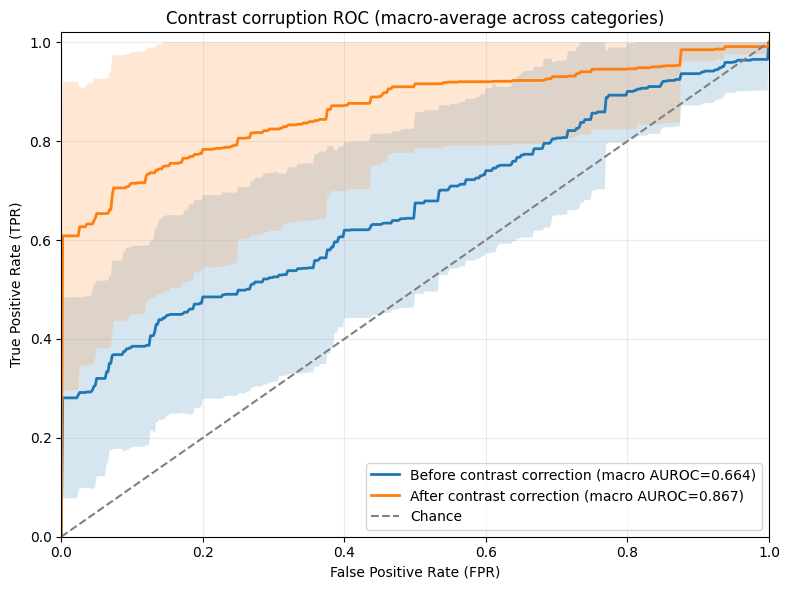

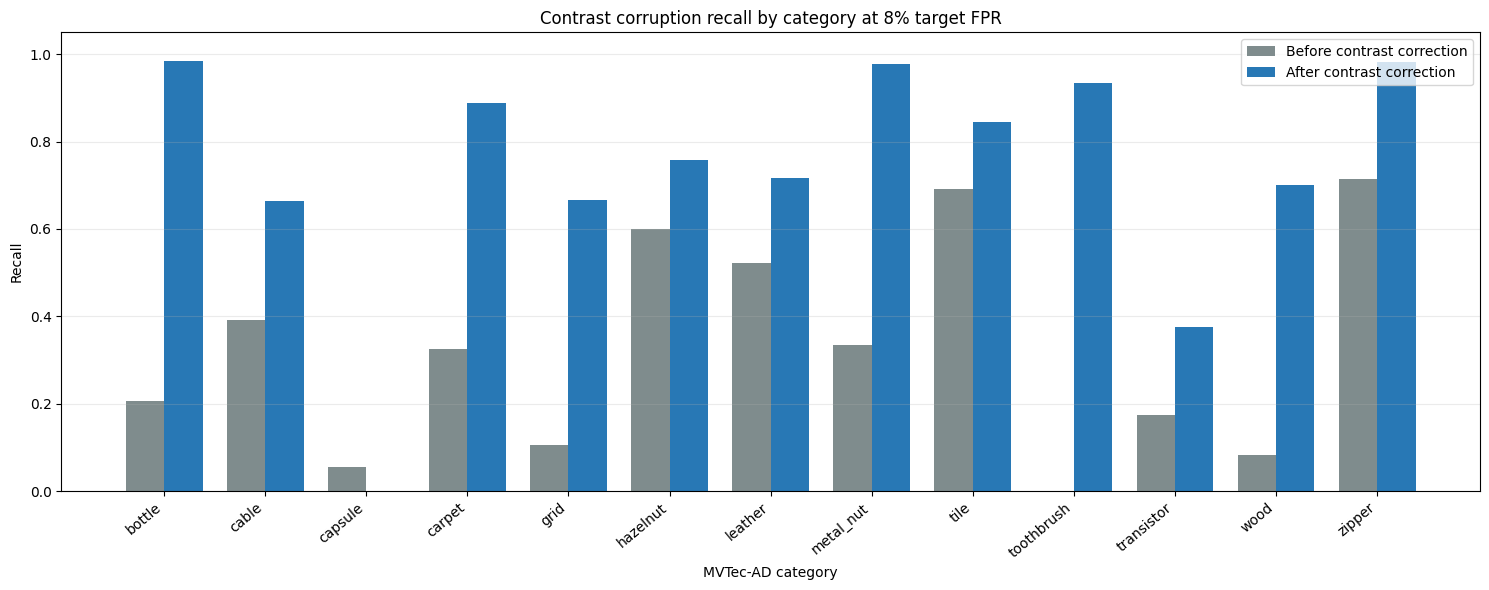

In [10]:
FPR_GRID = np.linspace(0.0, 1.0, 501)
roc_curves = {"before": [], "after": []}
roc_aucs = {"before": [], "after": []}
for record in roc_rows:
    labels = record["labels"]
    if np.unique(labels).size < 2:
        continue
    for name, score_key in (("before", "before_scores"), ("after", "after_scores")):
        fpr, tpr, _ = roc_curve(labels, record[score_key])
        tpr_interp = np.interp(FPR_GRID, fpr, tpr)
        tpr_interp[0] = 0.0
        roc_curves[name].append(tpr_interp)
        roc_aucs[name].append(roc_auc_score(labels, record[score_key]))

fig, ax = plt.subplots(figsize=(8, 6))
for name, label in (("before", "Before contrast correction"),
                    ("after", "After contrast correction")):
    curves = np.asarray(roc_curves[name])
    if curves.size == 0:
        continue
    mean_tpr = curves.mean(axis=0)
    std_tpr = curves.std(axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = float(np.mean(roc_aucs[name]))
    ax.plot(FPR_GRID, mean_tpr, linewidth=2,
            label=f"{label} (macro AUROC={mean_auc:.3f})")
    ax.fill_between(FPR_GRID, np.maximum(mean_tpr - std_tpr, 0),
                    np.minimum(mean_tpr + std_tpr, 1), alpha=0.18)
ax.plot([0, 1], [0, 1], "--", color="gray", label="Chance")
ax.set(xlim=(0, 1), ylim=(0, 1.02), xlabel="False Positive Rate (FPR)",
       ylabel="True Positive Rate (TPR)",
       title="Contrast corruption ROC (macro-average across categories)")
ax.grid(alpha=0.25)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()


plot_df = results_df.sort_values("category").reset_index(drop=True)
x = np.arange(len(plot_df))
width = 0.38
fig, ax = plt.subplots(figsize=(15, 6))
ax.bar(x - width/2, plot_df["recall_before"], width,
       label="Before contrast correction", color="#7f8c8d")
ax.bar(x + width/2, plot_df["recall_after"], width,
       label="After contrast correction", color="#2878B5")
ax.set_xticks(x, plot_df["category"], rotation=40, ha="right")
ax.set_ylim(0, 1.05)
ax.set_xlabel("MVTec-AD category")
ax.set_ylabel("Recall")
ax.set_title(f"Contrast corruption recall by category at {TARGET_FPR:.0%} target FPR")
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()